# DBSCAN: clustering by density

K-Means needs the number of clusters in advance and only finds round groups. DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) finds groups of any shape wherever the points are packed together, finds the number of clusters on its own, and leaves the isolated points aside as **noise**.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_blobs, make_circles, make_moons
from sklearn.metrics import pairwise_distances
import plotly.io as pio
import plotly.graph_objects as go
pio.templates["course"] = go.layout.Template(layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"])
pio.templates.default = "plotly_white+course"

# the same colours for matplotlib: one colour per cluster, grey for the noise
COLORS = ["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3"]
NOISE = "#999999"

def plot_clusters(ax, X, labels, title):
    # Scatter plot with one colour per cluster and the noise (label -1) as grey crosses
    for k in np.unique(labels):
        part = X[labels == k]
        if k == -1:
            ax.scatter(part[:, 0], part[:, 1], s=18, c=NOISE, marker="x", label="noise")
        else:
            ax.scatter(part[:, 0], part[:, 1], s=12, color=COLORS[k % len(COLORS)], label=f"cluster {k}")
    ax.set_title(title, fontsize=11)
    ax.set_xticks([])
    ax.set_yticks([])

## Why K-Means is not enough 🥵

K-Means puts each point with its nearest centroid. The border between two clusters is therefore a straight line, halfway between two centroids, and each cluster is a rough ball around its centroid. When the groups we are looking for are not ball-shaped, K-Means cannot find them, however we initialise it.

#### See it with data 🔬: two shapes that K-Means cannot separate

Two classic toy datasets: two interleaved half-moons, and a small ring inside a large one. Each has 400 points made of two groups. We ask K-Means for 2 clusters and count how many points end up with their true group.

K-Means on the moons: 76% of the points with their true group
K-Means on the rings: 51% of the points with their true group


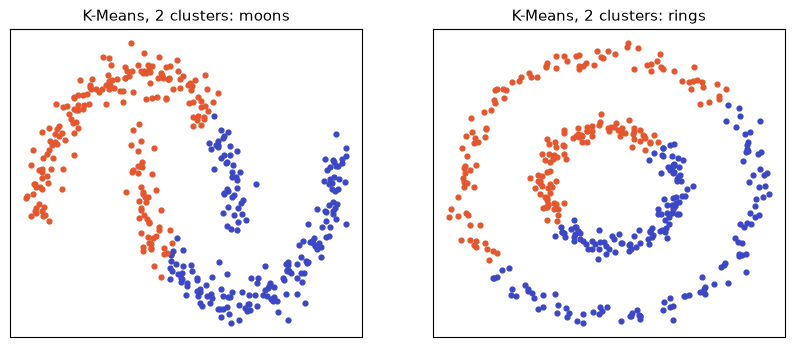

In [ ]:
X_moons, y_moons = make_moons(n_samples=400, noise=0.08, random_state=0)
X_rings, y_rings = make_circles(n_samples=400, factor=0.45, noise=0.05, random_state=0)

def share_correct(labels, truth):
    # Share of points put with their true group (cluster numbers 0/1 may be swapped)
    return max(np.mean(labels == truth), np.mean(labels != truth))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, X, y, name in [(axes[0], X_moons, y_moons, "moons"), (axes[1], X_rings, y_rings, "rings")]:
    km_labels = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X)
    print(f"K-Means on the {name}: {share_correct(km_labels, y):.0%} of the points with their true group")
    plot_clusters(ax, X, km_labels, f"K-Means, 2 clusters: {name}")
plt.show()

**What this shows:** on the moons, K-Means cuts the plane with a straight line and puts only 76% of the points with their true moon: the tip of each moon goes with the other one. On the rings it is even worse, 51%, no better than tossing a coin: K-Means cuts both rings in half, because the two rings have the same centre. The groups are perfectly visible to the eye, but they are defined by **continuity** (points close to each other), not by a centre.

## Density: a neighbourhood and a threshold 🧑‍🤝‍🧑

:::tip Intuition
Look at a country from a plane, at night. Towns are places where lights are packed together; a farm is a single light, far from the others. You don't need to know in advance how many towns there are, nor their shape: a town is simply a place where every light has many other lights close to it. DBSCAN works exactly like this.
:::

DBSCAN needs two settings:

* `eps` ($\varepsilon$): the radius of the **neighbourhood** of a point. The neighbourhood of $x$ is the set of points at a distance at most $\varepsilon$ from $x$ (the point $x$ itself included):
$$N_\varepsilon(x) = \{\, y \;:\; d(x, y) \le \varepsilon \,\}$$
* `min_samples`: the number of points a neighbourhood must contain to be called **dense**.

The **density** around a point is simply the number of points in its neighbourhood, $|N_\varepsilon(x)|$. From it, DBSCAN sorts the points into three kinds:

* A **core point** has a dense neighbourhood: $|N_\varepsilon(x)| \ge$ `min_samples`. Core points are the heart of the clusters.
* A **border point** is not a core point, but at least one of its neighbours is a core point. Border points sit at the edge of a cluster.
* A **noise point** (or outlier) is neither: few neighbours, and none of them is a core point.

⚠️ In scikit-learn, `min_samples` counts the point itself. With `min_samples=4`, a point is a core point if its circle contains the point and 3 other points. Some books count only the other points; check the convention when you compare values.

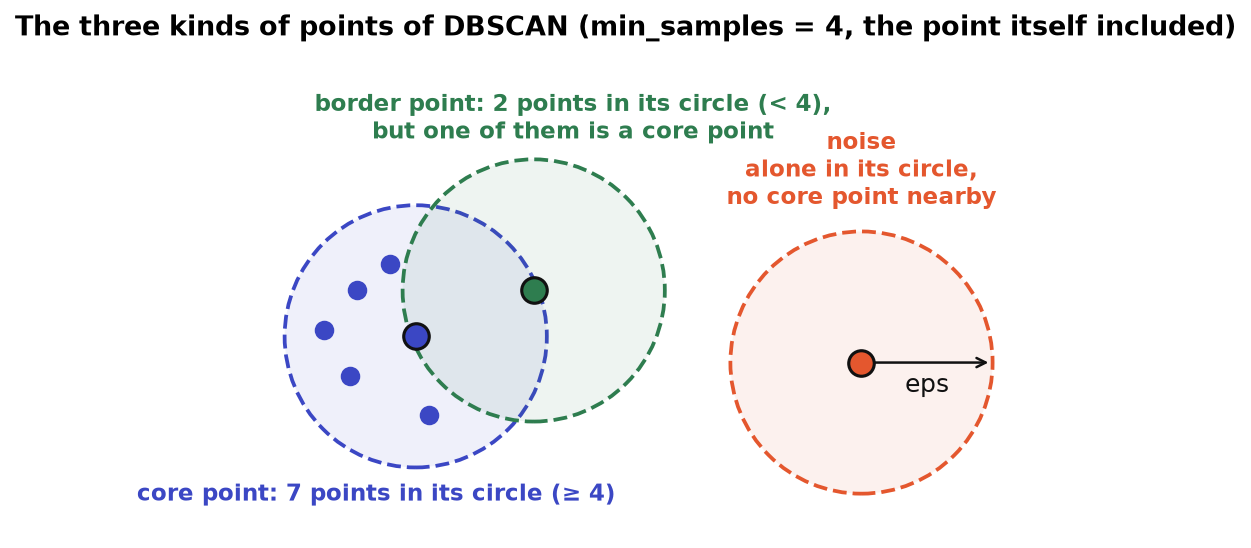

## The algorithm, step by step 📠

Once the core points are known, clusters grow from them like a rumour: a core point passes the cluster on to all its neighbours; a neighbour that is also a core point passes it on again, and so on. A border point receives the cluster but does not pass it on.

1. For every point, count the points in its neighbourhood $N_\varepsilon(x)$ and mark the core points.
2. Take a core point that has no cluster yet. It starts a new cluster.
3. Add all the points of its neighbourhood to this cluster. For every core point added, add its own neighbourhood too, and repeat until no new point can be added.
4. Go back to step 2 until every core point belongs to a cluster.
5. The points that never received a cluster are noise. Scikit-learn gives them the label **-1**.

Note that we never said how many clusters to find: it is a result of the algorithm, not a setting.

### On 13 points, by hand

Let's run the algorithm by hand on 13 points named A to M, with `eps=1.5` and `min_samples=4`.

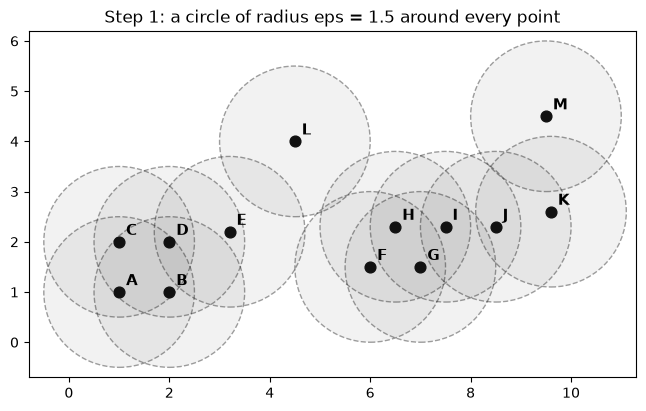

In [ ]:
points = pd.DataFrame({
    "x": [1, 2, 1, 2, 3.2, 6, 7, 6.5, 7.5, 8.5, 9.6, 4.5, 9.5],
    "y": [1, 1, 2, 2, 2.2, 1.5, 1.5, 2.3, 2.3, 2.3, 2.6, 4, 4.5],
}, index=list("ABCDEFGHIJKLM"))
X_small = points[["x", "y"]].to_numpy()
names = list(points.index)
eps, min_samples = 1.5, 4

def draw_points(ax, colors="#111111", circles=True):
    # The 13 points with their names, and (optionally) their circle of radius eps
    for (name, row), color in zip(points.iterrows(), np.broadcast_to(colors, len(points))):
        if circles:
            ax.add_patch(Circle((row.x, row.y), eps, facecolor=color, alpha=0.05, edgecolor="none"))
            ax.add_patch(Circle((row.x, row.y), eps, fill=False, edgecolor=color, alpha=0.4, ls="--"))
        ax.scatter(row.x, row.y, s=60, color=color, zorder=3)
        ax.annotate(name, (row.x, row.y), xytext=(5, 5), textcoords="offset points", fontsize=11, weight="bold")
    ax.set_xlim(-0.8, 11.3)
    ax.set_ylim(-0.7, 6.2)
    ax.set_aspect("equal")

fig, ax = plt.subplots(figsize=(9, 4.5))
draw_points(ax)
ax.set_title("Step 1: a circle of radius eps = 1.5 around every point")
plt.show()

**Step 1: count the points in each circle.** We compute all the distances between points and, for each point, list the points at a distance $\le 1.5$.

In [ ]:
distances = pairwise_distances(X_small)                  # 13 x 13 table of Euclidean distances
in_circle = distances <= eps                              # True when the column point is in the row point's circle

table = pd.DataFrame({
    "points in the circle": in_circle.sum(axis=1),        # the point itself is counted
    "neighbours": [", ".join(n for n, inside in zip(names, row) if inside and n != me)
                   for me, row in zip(names, in_circle)],
}, index=names)
table["core?"] = table["points in the circle"] >= min_samples
table

,points in the circle,neighbours,core?
A,4,"B, C, D",True
B,4,"A, C, D",True
C,4,"A, B, D",True
D,5,"A, B, C, E",True
E,2,D,False
F,3,"G, H",False
G,4,"F, H, I",True
H,4,"F, G, I",True
I,4,"G, H, J",True
J,3,"I, K",False


**Step 2: name the kind of each point.**

* A, B, C (4 points in their circle) and D (5 points) are **core** points. So are G, H and I (4 points each).
* E has only 2 points in its circle (itself and D), but D is a core point: E is a **border** point.
* F (3 points) is a border point thanks to its core neighbours G and H. J (3 points) is a border point thanks to I.
* K has 2 points in its circle (itself and J), and J is **not** a core point: K is **noise**, although it touches the cluster.
* L and M are alone in their circle: noise.

{'A': 'core', 'B': 'core', 'C': 'core', 'D': 'core', 'E': 'border', 'F': 'border', 'G': 'core', 'H': 'core', 'I': 'core', 'J': 'border', 'K': 'noise', 'L': 'noise', 'M': 'noise'}


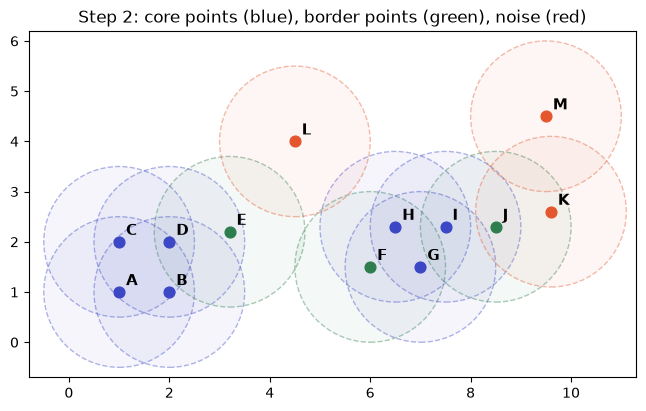

In [ ]:
is_core = table["core?"].to_numpy()
is_border = ~is_core & (in_circle & is_core).any(axis=1)   # not core, but a core point in its circle
kind = np.where(is_core, "core", np.where(is_border, "border", "noise"))
print(dict(zip(names, kind.tolist())))

KIND_COLORS = {"core": "#3B47C4", "border": "#2E7D4F", "noise": "#E4572E"}
fig, ax = plt.subplots(figsize=(9, 4.5))
draw_points(ax, colors=[KIND_COLORS[k] for k in kind])
ax.set_title("Step 2: core points (blue), border points (green), noise (red)")
plt.show()

**Step 3: grow the clusters.** The function below follows the algorithm literally and prints what it does. `to_visit` is the list of core points whose neighbourhood has not been added yet.

In [ ]:
def dbscan_by_hand(in_circle, is_core):
    labels = np.full(len(names), -1)                      # -1 = no cluster (yet)
    snapshots = []                                        # (labels, point being expanded), to draw the steps
    cluster = -1
    for start in range(len(names)):
        if not is_core[start] or labels[start] != -1:     # only an unassigned core point starts a cluster
            continue
        cluster += 1
        labels[start] = cluster
        print(f"Cluster {cluster} starts at core point {names[start]}")
        to_visit = [start]
        while to_visit:
            p = to_visit.pop(0)
            new = [q for q in np.where(in_circle[p])[0] if labels[q] == -1]
            for q in new:
                labels[q] = cluster
                if is_core[q]:
                    to_visit.append(q)                    # a core point will pass the cluster on
            if new:
                added = ", ".join(names[q] + ("" if is_core[q] else " (border, stops here)") for q in new)
                print(f"   {names[p]} adds {added}")
                snapshots.append((labels.copy(), p))
    return labels, snapshots

labels_by_hand, snapshots = dbscan_by_hand(in_circle, is_core)
print("Final labels:", dict(zip(names, labels_by_hand.tolist())))

Cluster 0 starts at core point A
   A adds B, C, D
   D adds E (border, stops here)
Cluster 1 starts at core point G
   G adds F (border, stops here), H, I
   I adds J (border, stops here)
Final labels: {'A': 0, 'B': 0, 'C': 0, 'D': 0, 'E': 0, 'F': 1, 'G': 1, 'H': 1, 'I': 1, 'J': 1, 'K': -1, 'L': -1, 'M': -1}


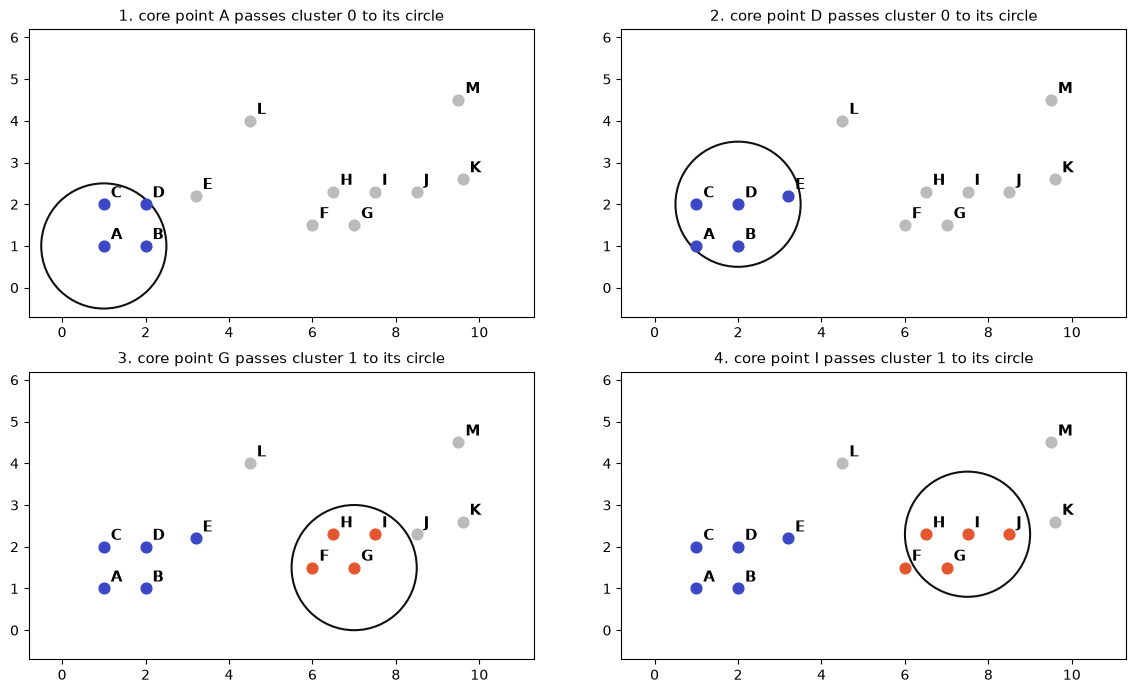

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for i, (ax, (labels, p)) in enumerate(zip(axes.ravel(), snapshots)):
    colors = [COLORS[l] if l >= 0 else "#BBBBBB" for l in labels]
    draw_points(ax, colors=colors, circles=False)
    ax.add_patch(Circle(X_small[p], eps, fill=False, edgecolor="#111111", lw=1.5))
    ax.set_title(f"{i + 1}. core point {names[p]} passes cluster {labels[p]} to its circle", fontsize=11)
plt.tight_layout()
plt.show()

**What this shows:** in grey, the points without a cluster yet. Cluster 0 starts at A, which adds B, C and D. B and C bring nobody new, D adds E. E is a border point, so the growth stops there. Cluster 1 starts at the next unassigned core point, F being only a border point: G adds F, H and I; I adds J; J is a border point, so K is never reached. K, L and M keep the label -1: noise. We found 2 clusters without asking for 2.

**Step 4: check with scikit-learn.** After `fit`, `labels_` holds the cluster of each point (-1 for noise) and `core_sample_indices_` the positions of the core points.

In [ ]:
db = DBSCAN(eps=1.5, min_samples=4).fit(X_small)

check = pd.DataFrame({
    "by hand": labels_by_hand,
    "scikit-learn": db.labels_,
    "core by hand": is_core,
    "core for scikit-learn": np.isin(np.arange(len(names)), db.core_sample_indices_),
}, index=names)
print("Same labels:", (check["by hand"] == check["scikit-learn"]).all(),
      "| same core points:", (check["core by hand"] == check["core for scikit-learn"]).all())
print("core_sample_indices_:", db.core_sample_indices_, "->", [names[i] for i in db.core_sample_indices_])
check.T

Same labels: True | same core points: True
core_sample_indices_: [0 1 2 3 6 7 8] -> ['A', 'B', 'C', 'D', 'G', 'H', 'I']


,A,B,C,D,E,F,G,H,I,J,K,L,M
by hand,0,0,0,0,0,1,1,1,1,1,-1,-1,-1
scikit-learn,0,0,0,0,0,1,1,1,1,1,-1,-1,-1
core by hand,True,True,True,True,False,False,True,True,True,False,False,False,False
core for scikit-learn,True,True,True,True,False,False,True,True,True,False,False,False,False


**What this shows:** scikit-learn finds exactly the same 2 clusters, the same 7 core points (A, B, C, D, G, H, I) and the same 3 noise points (K, L, M). The algorithm really is just "count the neighbours, then spread from the core points".

One detail: a border point that touches two clusters goes to the cluster that reaches it **first**. This depends on the order of the data, but it is rare and only concerns border points: core points and noise never depend on the order.

## DBSCAN finds the shapes K-Means missed 🎯

#### See it with data 🔬: moons and rings

Back to the two datasets of the beginning. We use the same settings for both: `eps=0.16` and `min_samples=5`.

DBSCAN on the moons: 2 clusters, 1 noise point(s), 100% of the other points with their true group
DBSCAN on the rings: 2 clusters, 0 noise point(s), 100% of the other points with their true group


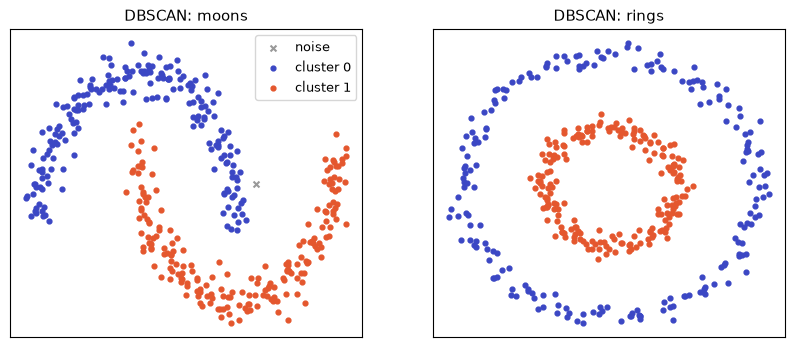

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, X, y, name in [(axes[0], X_moons, y_moons, "moons"), (axes[1], X_rings, y_rings, "rings")]:
    labels = DBSCAN(eps=0.16, min_samples=5).fit_predict(X)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    kept = labels != -1
    print(f"DBSCAN on the {name}: {n_clusters} clusters, {(~kept).sum()} noise point(s), "
          f"{share_correct(labels[kept], y[kept]):.0%} of the other points with their true group")
    plot_clusters(ax, X, labels, f"DBSCAN: {name}")
axes[0].legend(fontsize=9)
plt.show()

**What this shows:** DBSCAN finds the 2 moons and the 2 rings, and puts 100% of the clustered points with their true group, where K-Means scored 76% and 51%. Nobody told it there were 2 groups. On the moons, 1 isolated point is labelled noise (grey cross): DBSCAN prefers to leave it aside rather than force it into a cluster.

Each ring is a chain of dense neighbourhoods: from any point of a ring, you can walk to any other point in small steps of less than `eps`, always through core points. Between the two rings there is a gap wider than `eps`, so the rumour cannot cross it.

## The effect of `eps` and `min_samples` 🎛️

:::tip Intuition
`eps` and `min_samples` together define what "crowded" means: "at least `min_samples` people within `eps` metres". A larger `eps` or a smaller `min_samples` makes the rule easier to satisfy: more core points, larger clusters that end up merging, less noise. A smaller `eps` or a larger `min_samples` makes it stricter: clusters break into pieces and more points become noise.
:::

#### See it with data 🔬: six settings on the moons

Top row: `min_samples=5` and three values of `eps`. Bottom row: `eps=0.16` and three values of `min_samples`.

eps=0.05  min_samples=5   -> 17 clusters, 297 noise points
eps=0.16  min_samples=5   ->  2 clusters,   1 noise points


eps=0.4   min_samples=5   ->  1 clusters,   0 noise points
eps=0.16  min_samples=2   ->  2 clusters,   1 noise points
eps=0.16  min_samples=10  ->  2 clusters,   4 noise points
eps=0.16  min_samples=20  ->  8 clusters, 216 noise points


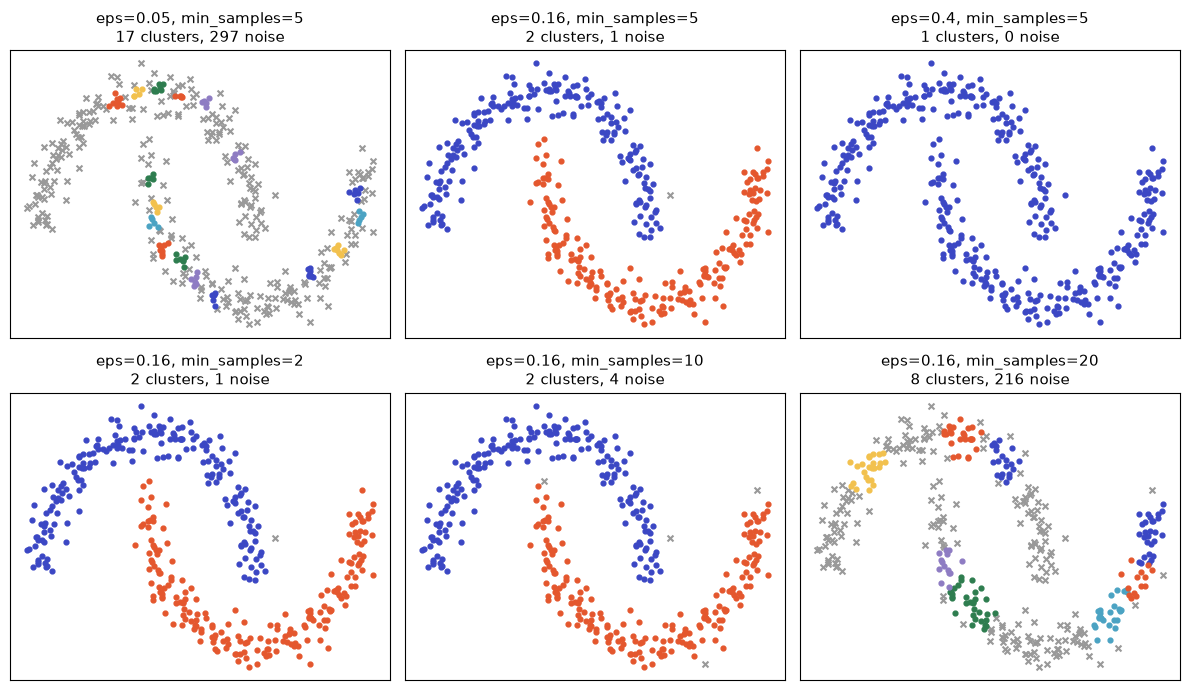

In [ ]:
settings = [(0.05, 5), (0.16, 5), (0.4, 5), (0.16, 2), (0.16, 10), (0.16, 20)]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, (e, m) in zip(axes.ravel(), settings):
    labels = DBSCAN(eps=e, min_samples=m).fit_predict(X_moons)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()
    print(f"eps={e:<5} min_samples={m:<3} -> {n_clusters:>2} clusters, {n_noise:>3} noise points")
    plot_clusters(ax, X_moons, labels, f"eps={e}, min_samples={m}\n{n_clusters} clusters, {n_noise} noise")
plt.tight_layout()
plt.show()

**What this shows:**

* `eps=0.05` is too small: few points have 5 points within such a tiny radius, so 297 of the 400 points are noise and the rest is cut into 17 small clusters.
* `eps=0.4` is too large: the neighbourhoods reach across the gap between the moons, and everything is merged into 1 cluster with no noise.
* With `min_samples=2`, every point that has a single neighbour is a core point: still 2 clusters here, and only 1 noise point, but the rule is so loose that any small group of noise points would form its own cluster.
* With `min_samples=10`, the result barely changes (4 noise points instead of 1). With `min_samples=20`, the rule is too strict for this data: the moons fall apart into 8 pieces and 216 points become noise.

In short:

| | small `min_samples` | large `min_samples` |
|---|---|---|
| **small `eps`** | many small clusters, sensitive to noise | dense cores only, a lot of noise |
| **large `eps`** | few large clusters, almost no noise (clusters merge) | large clusters, isolated points still treated as noise |

The next lesson shows how to choose these two values with a method rather than by trial and error.

## Noise: DBSCAN does not force every point into a cluster 🔇

K-Means puts **every** point in a cluster, even a point that is far from everything. DBSCAN can answer "this point belongs to no group": its label is -1. This makes DBSCAN useful for finding outliers, and it keeps the clusters clean.

#### See it with data 🔬: three groups and 30 stray points

We draw 3 groups of 150 points and add 30 points spread at random over the whole area. Then we compare K-Means (3 clusters) and DBSCAN.

K-Means: stray points put in a cluster: 30 out of 30
DBSCAN : stray points labelled noise   : 24 out of 30
DBSCAN : group points labelled noise   : 5 out of 450
DBSCAN : number of clusters            : 3


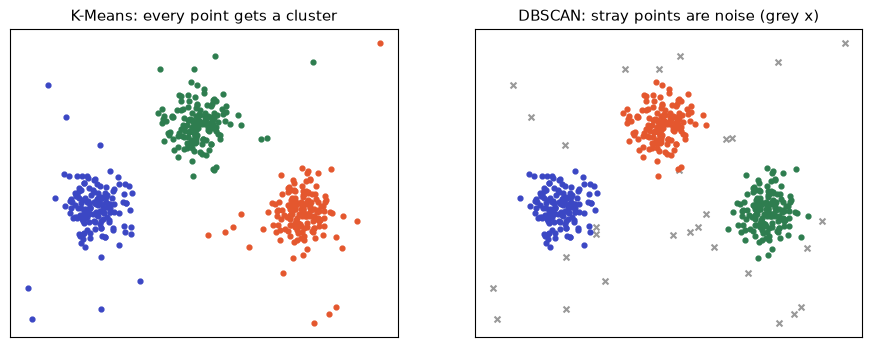

In [ ]:
X_blobs, _ = make_blobs(n_samples=450, centers=[[-4, 0], [0, 3], [4, 0]], cluster_std=0.6, random_state=0)
rng = np.random.default_rng(0)
X_stray = rng.uniform(low=[-7, -4], high=[7, 6], size=(30, 2))
X_noisy = np.vstack([X_blobs, X_stray])
is_stray = np.r_[np.zeros(450, bool), np.ones(30, bool)]

km_labels = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(X_noisy)
db_labels = DBSCAN(eps=0.6, min_samples=8).fit_predict(X_noisy)

print("K-Means: stray points put in a cluster:", (km_labels[is_stray] != -1).sum(), "out of 30")
print("DBSCAN : stray points labelled noise   :", (db_labels[is_stray] == -1).sum(), "out of 30")
print("DBSCAN : group points labelled noise   :", (db_labels[~is_stray] == -1).sum(), "out of 450")
print("DBSCAN : number of clusters            :", len(set(db_labels)) - 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_clusters(axes[0], X_noisy, km_labels, "K-Means: every point gets a cluster")
plot_clusters(axes[1], X_noisy, db_labels, "DBSCAN: stray points are noise (grey x)")
plt.show()

**What this shows:** K-Means puts all 30 stray points in a cluster: a point far in a corner still "belongs" to its nearest centroid, and it pulls this centroid towards it. DBSCAN finds the 3 groups and labels 24 of the 30 stray points as noise (the others happen to fall inside or right next to a group, where nobody could tell them apart). It also labels 5 of the 450 points of the groups as noise: the most isolated points at their edges.

## Limits of DBSCAN ⚠️

* **One density for the whole dataset.** `eps` and `min_samples` are the same everywhere. If one cluster is much more spread out than another, no single value fits both (see below).
* **High dimensions.** With many features, all the distances become large and similar to each other, so "dense" loses its meaning. DBSCAN works best in low dimension: 2 or 3 coordinates, typically **spatial data** (positions on a map, GPS points, positions in a room).
* **Scaling.** `eps` is one radius in every direction, so the features must be on comparable scales (next lesson).
* **No `predict` for new points.** Scikit-learn's `DBSCAN` has `fit` and `fit_predict`, but no `predict`: to place new points, you run the algorithm again on all the data.

#### See it with data 🔬: a dense group next to a spread-out group

Two tight groups (spread 0.25, 200 points each) close to each other, and one wide group (spread 1.5, 300 points) further away. We try a small and a large `eps`, with `min_samples=10`.

eps=0.3: 4 clusters | the two tight groups merged: False | noise in the wide group: 284 of 300
eps=0.8: 2 clusters | the two tight groups merged: True | noise in the wide group: 19 of 300


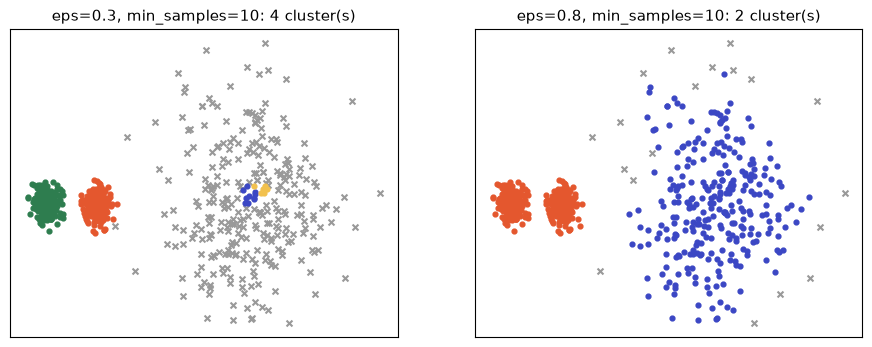

In [ ]:
X_dens, y_dens = make_blobs(n_samples=[200, 200, 300], centers=[[0, 0], [1.8, 0], [7, 0]],
                            cluster_std=[0.25, 0.25, 1.5], random_state=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, e in zip(axes, [0.3, 0.8]):
    labels = DBSCAN(eps=e, min_samples=10).fit_predict(X_dens)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    merged = set(labels[y_dens == 0]) == set(labels[y_dens == 1])
    print(f"eps={e}: {n_clusters} clusters | the two tight groups merged: {merged} | "
          f"noise in the wide group: {(labels[y_dens == 2] == -1).sum()} of 300")
    plot_clusters(ax, X_dens, labels, f"eps={e}, min_samples=10: {n_clusters} cluster(s)")
plt.show()

**What this shows:** with `eps=0.3`, the two tight groups are found and kept apart, but 284 of the 300 points of the wide group are labelled noise (in such a spread-out group, few points have 10 neighbours within 0.3), and the rest of it forms 2 tiny clusters: 4 clusters instead of 3. With `eps=0.8`, the wide group is found (only 19 noise points), but the two tight groups are now merged into one cluster: the larger radius bridges the small gap between them. No single `eps` suits both densities. When the density varies a lot from one region to another, look at HDBSCAN (`sklearn.cluster.HDBSCAN`), a variant of DBSCAN that adapts to the local density.

## Summary ✅

| Advantages | Drawbacks |
|---|---|
| Finds clusters of any shape and size | One `eps` for the whole dataset: struggles when the density varies between clusters |
| Finds the number of clusters on its own | Two settings to choose, `eps` and `min_samples`, in the units of the data |
| Detects noise (label -1): outliers do not distort the clusters | Loses its meaning in high dimension; needs scaled features |
| Deterministic: core points and noise do not depend on the order of the data | No `predict` for new points |

DBSCAN shines on **spatial data**: where do the points concentrate on a map, in a store, in a city? That's exactly what the exercise of this section does with emergency calls.

**To remember:**
* the neighbourhood of radius `eps`, and `min_samples` points to make it dense (the point itself included in scikit-learn);
* core points, border points, noise; clusters grow from core points only;
* `labels_` gives the cluster of each point, -1 for noise; `core_sample_indices_` gives the core points.

## Resources 📚
* [DBSCAN in the scikit-learn user guide](https://scikit-learn.org/stable/modules/clustering.html#dbscan)
* M. Ester, H.-P. Kriegel, J. Sander and X. Xu, *A density-based algorithm for discovering clusters in large spatial databases with noise*, KDD 1996: the original paper.